# OE2B-03 — Construcción del dataset de pares

Este notebook construye el dataset de pares **(A, B, etiqueta)** que va a usar xnorC para entrenamiento y validación.

---

## ¿Por qué pares?

El modelo xnorC no aprende a clasificar directamente "este audio es QR" o "este audio es QL".
En cambio, aprende a responder una pregunta más simple: **"¿estos dos audios suenan parecido?"**

La ventaja de este enfoque es que el modelo nunca aprende el sonido absoluto de una colmena particular.
Aprende a comparar. Cuando llega una colmena nueva que nunca vio, puede comparar su audio contra
una referencia etiquetada y decidir si son iguales o diferentes.

Esto es exactamente lo que necesitamos para generalizar entre colmenas de distintos países.

---

## Estructura de un par

Cada par es simplemente dos fragmentos de audio de la **misma colmena**, junto con una etiqueta:

```
Par = (audio_A, audio_B, etiqueta)
```

| etiqueta | significado | ejemplo |
|---|---|---|
| **1 — IGUAL** | los dos audios son del mismo estado | QR + QR, o QL + QL |
| **0 — DIFERENTE** | los dos audios son de estados distintos | QR + QL |

Durante el entrenamiento, xnorC recibe miles de estos pares y aprende qué características del audio
cambian entre QR y QL, y cuáles se mantienen estables.

---

## Las 5 reglas de construcción

No todos los pares son igual de útiles. Estas reglas aseguran que el dataset sea representativo
y que el modelo no haga trampa durante la evaluación.

### R1 — Mismo origen
Los dos audios de un par deben ser de la **misma colmena**.

*¿Por qué?* El objetivo es que el modelo aprenda las diferencias acústicas entre QR y QL
dentro de una misma colmena. Si mezclamos colmenas distintas, el modelo podría aprender
simplemente a reconocer el "timbre" de cada colmena en lugar del estado de la reina.

### R2 — Sin leakage entre train y test
Nunca puede haber datos de la misma colmena en el conjunto de entrenamiento **y** en el de evaluación al mismo tiempo.

*¿Por qué?* Si el modelo vio audios de la colmena X durante el entrenamiento, ya conoce su
"timbre particular". Evaluar sobre la misma colmena X daría resultados inflados que no reflejan
la capacidad real de generalizar a colmenas nuevas. Con k-hive-fold garantizamos que la colmena
de evaluación siempre sea completamente nueva para el modelo.

### R3 — Balance 50/50
El dataset debe tener la misma cantidad de pares IGUAL que pares DIFERENTE.

*¿Por qué?* Si hay muchos más pares DIFERENTE que IGUAL, el modelo aprende que "casi siempre
la respuesta es DIFERENTE" y se sesga hacia ese resultado. Con balance 50/50 el modelo no
puede ganar puntos simplemente apostando siempre a la misma clase.

### R4 — Pares DIFERENTE cerca de la transición
Los pares QR+QL se construyen usando audios grabados en los días cercanos al cambio de estado
(dentro de una ventana de ± `DIAS_MARGEN_TRANSICION` días alrededor de la transición).

*¿Por qué?* Los días más cercanos a la transición son los más difíciles de clasificar: el audio
QR todavía no cambió mucho y el audio QL tampoco es tan distinto. Si el modelo aprende a
distinguirlos en el momento más difícil, generaliza mejor. Además, esto evita usar
pares con diferencias acústicas triviales (ej: QR de hace 2 meses vs QL de hoy).

*Excepción:* NU-HIVE es un experimento de laboratorio donde el apicultor retiró la reina
deliberadamente. Entre el período QL y el período QR hay un gap de días sin datos, así que
no existe una "transición continua" que detectar. Para NU-HIVE se usan todos los archivos
disponibles sin restricción de distancia.

### R5 — Pares IGUAL en períodos estables
Los pares QR+QR y QL+QL se construyen usando audios grabados lejos de cualquier transición
(a más de `DIAS_ESTABILIDAD_MINIMA` días de distancia).

*¿Por qué?* Los días justo antes o después de un cambio de estado son ambiguos: la colonia
puede estar en transición acústica aunque el estado oficial no haya cambiado todavía. Usar
audios de períodos estables asegura que los pares IGUAL realmente suenen parecidos entre sí,
lo cual es necesario para que el modelo aprenda una señal útil.

---

## K-hive-fold: la validación cruzada correcta para este problema

La validación cruzada estándar (random split) **no funciona** para medir generalización entre colmenas.
Si mezclamos aleatoriamente los datos, el modelo ve audios de todas las colmenas durante el entrenamiento
y luego lo evaluamos sobre las mismas colmenas — lo que mide es memorización, no generalización.

El k-hive-fold resuelve esto:

```
Colmenas disponibles: A, B, C, D

Fold 0: train = {B, C, D}  →  test = {A}
Fold 1: train = {A, C, D}  →  test = {B}
Fold 2: train = {A, B, D}  →  test = {C}
Fold 3: train = {A, B, C}  →  test = {D}
```

En cada fold, la colmena de test es completamente nueva para el modelo.
El resultado final es el promedio de los 4 folds — una medida honesta de
cuánto generaliza el modelo a colmenas que nunca vio.

---

## Datasets usados

| Dataset | Colmenas | Tipo | Uso en xnorC |
|---|---|---|---|
| Yang | varias colmenas, California EE.UU. | natural (apicultor controla el cambio) | Train + validación (k-hive-fold) |
| NU-HIVE | Hive1 y Hive3 | controlado (gap entre períodos) | Train + validación (k-hive-fold) |
| UrBAN 2021 | 6 colmenas, Francia | field recording | Evaluación cross-country (OE2B-07) |

## Outputs

- `../data/processed/pares/pares_completo.csv` — todos los pares con metadatos
- `../data/processed/pares/folds/fold_{k}_train.csv` — pares de entrenamiento del fold k
- `../data/processed/pares/folds/fold_{k}_test.csv`  — pares de validación del fold k

**No modifica ningún archivo de audio.**

## Configuración

In [1]:
from pathlib import Path

# ─── RUTAS DE ENTRADA ────────────────────────────────────────────────────────
# Inventarios generados en OE2B-01 y OE2B-02
RUTA_INV_YANG   = Path("../data/processed/yang/yang_audio_inventario.csv")
RUTA_INV_NUHIVE = Path("../data/processed/nuhive/nuhive_inventario.csv")

# ─── RUTAS DE SALIDA ─────────────────────────────────────────────────────────
RUTA_PARES      = Path("../data/processed/pares/pares_completo.csv")
RUTA_FOLDS      = Path("../data/processed/pares/folds")

# ─── PARÁMETROS ──────────────────────────────────────────────────────────────
# Cuántos pares DIFERENTE construir por colmena (IGUAL = misma cantidad → balance 50/50)
# Si la colmena tiene menos datos, se usan todos los disponibles
MAX_PARES_DIFERENTE_POR_COLMENA = 500

# Margen de días alrededor de la transición para elegir pares DIFERENTE (R4)
# Ej: 7 → tomamos muestras de los 7 días antes y después del cambio QR→QL
DIAS_MARGEN_TRANSICION = 7

# Días mínimos de distancia a la transición para pares IGUAL estables (R5)
# Ej: 3 → no usamos muestras de los 3 días más cercanos al cambio de estado
DIAS_ESTABILIDAD_MINIMA = 3

# Semilla para reproducibilidad
SEMILLA = 42
# ─────────────────────────────────────────────────────────────────────────────

RUTA_PARES.parent.mkdir(parents=True, exist_ok=True)
RUTA_FOLDS.mkdir(parents=True, exist_ok=True)

print("Configuración lista")
print(f"  Inventario Yang:   {RUTA_INV_YANG} — existe: {RUTA_INV_YANG.exists()}")
print(f"  Inventario NU-HIVE:{RUTA_INV_NUHIVE} — existe: {RUTA_INV_NUHIVE.exists()}")

Configuración lista
  Inventario Yang:   ../data/processed/yang/yang_audio_inventario.csv — existe: True
  Inventario NU-HIVE:../data/processed/nuhive/nuhive_inventario.csv — existe: True


## Importaciones

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from itertools import combinations

rng = np.random.default_rng(SEMILLA)
print("Importaciones listas")

Importaciones listas


---
## 1. Cargar inventarios

Cargamos los inventarios generados en OE2B-01 (NU-HIVE) y OE2B-02 (Yang).
Combinamos ambos en un único DataFrame con una columna `dataset` para identificar el origen.

In [3]:
# Cargar inventario Yang
df_yang = pd.read_csv(RUTA_INV_YANG, parse_dates=['timestamp'])
df_yang['dataset']       = 'yang'
df_yang['es_controlado'] = False   # Yang: transición natural continua → aplicar R4 y R5
df_yang['colmena_global'] = 'yang_' + df_yang['colmena_id'].astype(str)

# Cargar inventario NU-HIVE
df_nuhive = pd.read_csv(RUTA_INV_NUHIVE, parse_dates=['timestamp'])
df_nuhive['dataset']       = 'nuhive'
df_nuhive['es_controlado'] = True  # NU-HIVE: experimento controlado con gap entre períodos
df_nuhive['colmena_global'] = 'nuhive_' + df_nuhive['colmena_id'].astype(str)

# Solo usar archivos con etiqueta
df_yang   = df_yang[df_yang['estado'].notna()].copy()
df_nuhive = df_nuhive[df_nuhive['estado'].notna()].copy()

# Combinar
df_all = pd.concat([df_yang, df_nuhive], ignore_index=True)
df_all['fecha'] = pd.to_datetime(df_all['fecha']).dt.date

print("Inventario combinado:")
print()
resumen = df_all.groupby(['dataset', 'colmena_global', 'estado']).size().unstack(fill_value=0)
resumen['total'] = resumen.sum(axis=1)
print(resumen.to_string())
print()
print(f"Total archivos: {len(df_all):,}")
print(f"Colmenas únicas: {df_all['colmena_global'].nunique()}")

Inventario combinado:

estado                    QL    QR  total
dataset colmena_global                   
nuhive  nuhive_1         144   144    288
        nuhive_3         144   144    288
yang    yang_1          1012  2115   3127
        yang_2          1487  2486   3973

Total archivos: 7,676
Colmenas únicas: 4


---
## 2. Detectar fechas de transición por colmena

Para aplicar R4 (pares DIFERENTE cerca de la transición) y R5 (pares IGUAL lejos de la transición),
necesitamos saber cuándo cambia el estado en cada colmena.

Una transición es el día en que el estado pasa de QR a QL (o viceversa).

In [4]:
def detectar_transiciones(df_colmena):
    """
    Dado el DataFrame de una colmena, detecta los días de transición QR↔QL.
    Devuelve una lista de fechas donde ocurre el cambio.
    """
    # Un estado por día (tomamos el estado más frecuente del día)
    estado_por_dia = (
        df_colmena.groupby('fecha')['estado']
        .agg(lambda x: x.mode().iloc[0])
        .reset_index()
        .sort_values('fecha')
    )
    
    transiciones = []
    estados = estado_por_dia['estado'].values
    fechas  = estado_por_dia['fecha'].values
    
    for i in range(1, len(estados)):
        if estados[i] != estados[i-1]:
            # El día de transición es el primer día del nuevo estado
            transiciones.append(pd.Timestamp(fechas[i]).date())
    
    return transiciones


# Detectar transiciones para cada colmena
transiciones_por_colmena = {}

for colmena in df_all['colmena_global'].unique():
    df_col = df_all[df_all['colmena_global'] == colmena]
    trans  = detectar_transiciones(df_col)
    transiciones_por_colmena[colmena] = trans
    if trans:
        print(f"  {colmena}: transición detectada en {trans}")
    else:
        print(f"  {colmena}: ⚠️  sin transición detectada (solo un estado)")

  yang_2: transición detectada en [datetime.date(2022, 6, 9), datetime.date(2022, 6, 14), datetime.date(2022, 6, 26), datetime.date(2022, 7, 2)]
  yang_1: transición detectada en [datetime.date(2022, 6, 13), datetime.date(2022, 6, 26), datetime.date(2022, 6, 30)]
  nuhive_1: transición detectada en [datetime.date(2018, 6, 12)]
  nuhive_3: transición detectada en [datetime.date(2017, 7, 28)]


---
## 3. Calcular distancia a la transición

Para cada fila del inventario, calculamos cuántos días de distancia tiene a la transición más cercana.
Esto nos permite aplicar R4 y R5 al momento de construir los pares.

In [5]:
def distancia_a_transicion_mas_cercana(fecha, transiciones):
    """
    Calcula cuántos días separan 'fecha' de la transición más cercana.
    Si no hay transiciones, devuelve 999 (muy lejos → siempre estable).
    """
    if not transiciones:
        return 999
    fecha_ts = pd.Timestamp(fecha)
    distancias = [abs((fecha_ts - pd.Timestamp(t)).days) for t in transiciones]
    return min(distancias)


# Agregar columna de distancia a transición
df_all['dias_a_transicion'] = df_all.apply(
    lambda fila: distancia_a_transicion_mas_cercana(
        fila['fecha'],
        transiciones_por_colmena.get(fila['colmena_global'], [])
    ),
    axis=1
)

print("Distribución de distancia a transición:")
print(df_all['dias_a_transicion'].describe().round(1).to_string())
print()
print("Archivos cerca de transición (≤ 7 días):")
print(df_all[df_all['dias_a_transicion'] <= 7].groupby(['dataset', 'estado']).size()
      .rename('n').to_string())

Distribución de distancia a transición:
count    7676.0
mean        4.2
std         4.1
min         0.0
25%         1.0
50%         2.0
75%         7.0
max        15.0

Archivos cerca de transición (≤ 7 días):
dataset  estado
nuhive   QR         288
yang     QL        2499
         QR        3248


---
## 4. Construir pares

Construimos los pares para cada colmena por separado (R1: mismo origen).

**Par DIFERENTE (etiqueta=0):**
- 1 fragmento QR + 1 fragmento QL de la misma colmena
- Ambos dentro del margen de DIAS_MARGEN_TRANSICION alrededor de la transición (R4)

**Par IGUAL (etiqueta=1):**
- 2 fragmentos QR o 2 fragmentos QL de la misma colmena
- Ambos a más de DIAS_ESTABILIDAD_MINIMA días de cualquier transición (R5)
- Mitad QR+QR, mitad QL+QL para no sesgar hacia una clase

In [6]:
def construir_pares_colmena(df_col, max_pares_dif, dias_margen, dias_estab, rng_local):
    """
    Construye pares IGUAL y DIFERENTE para una colmena.

    - es_controlado=True  (NU-HIVE): usa todos los archivos sin filtrar por distancia
    - es_controlado=False (Yang):    aplica R4 (DIFERENTE cerca transición) y
                                     R5 (IGUAL lejos de transición)

    Devuelve una lista de dicts con los campos de cada par.
    """
    pares = []

    # Leer la bandera directamente del DataFrame (definida al cargar el inventario)
    es_controlado = df_col['es_controlado'].iloc[0]

    if es_controlado:
        # Dataset controlado (NU-HIVE): todos los archivos son candidatos
        cand_qr_dif = df_col[df_col['estado'] == 'QR']
        cand_ql_dif = df_col[df_col['estado'] == 'QL']
        cand_qr_ig  = df_col[df_col['estado'] == 'QR']
        cand_ql_ig  = df_col[df_col['estado'] == 'QL']
    else:
        # Dataset natural (Yang): aplicar R4 y R5
        cand_qr_dif = df_col[
            (df_col['estado'] == 'QR') &
            (df_col['dias_a_transicion'] <= dias_margen)
        ]
        cand_ql_dif = df_col[
            (df_col['estado'] == 'QL') &
            (df_col['dias_a_transicion'] <= dias_margen)
        ]
        cand_qr_ig = df_col[
            (df_col['estado'] == 'QR') &
            (df_col['dias_a_transicion'] > dias_estab)
        ]
        cand_ql_ig = df_col[
            (df_col['estado'] == 'QL') &
            (df_col['dias_a_transicion'] > dias_estab)
        ]

    n_dif = min(max_pares_dif, len(cand_qr_dif), len(cand_ql_dif))

    if n_dif == 0:
        return []

    # ── Construir pares DIFERENTE ──
    idx_qr = rng_local.choice(len(cand_qr_dif), size=n_dif, replace=False)
    idx_ql = rng_local.choice(len(cand_ql_dif), size=n_dif, replace=False)
    sel_qr = cand_qr_dif.iloc[idx_qr].reset_index(drop=True)
    sel_ql = cand_ql_dif.iloc[idx_ql].reset_index(drop=True)

    for i in range(n_dif):
        pares.append({
            'ruta_a':         sel_qr.loc[i, 'ruta'],
            'estado_a':       'QR',
            'colmena_a':      sel_qr.loc[i, 'colmena_global'],
            'fecha_a':        sel_qr.loc[i, 'fecha'],
            'dataset_a':      sel_qr.loc[i, 'dataset'],
            'ruta_b':         sel_ql.loc[i, 'ruta'],
            'estado_b':       'QL',
            'colmena_b':      sel_ql.loc[i, 'colmena_global'],
            'fecha_b':        sel_ql.loc[i, 'fecha'],
            'dataset_b':      sel_ql.loc[i, 'dataset'],
            'etiqueta':       0,
            'colmena_origen': sel_qr.loc[i, 'colmena_global'],
            'es_controlado':  es_controlado,
        })

    # ── Construir pares IGUAL (mitad QR+QR, mitad QL+QL) ──
    n_ig_qr = n_dif // 2
    n_ig_ql = n_dif - n_ig_qr

    # QR + QR
    if len(cand_qr_ig) >= 2 and n_ig_qr > 0:
        n_ig_qr = min(n_ig_qr, len(cand_qr_ig) // 2)
        idx_a = rng_local.choice(len(cand_qr_ig), size=n_ig_qr * 2, replace=False)
        sel_a = cand_qr_ig.iloc[idx_a[:n_ig_qr]].reset_index(drop=True)
        sel_b = cand_qr_ig.iloc[idx_a[n_ig_qr:]].reset_index(drop=True)
        for i in range(n_ig_qr):
            pares.append({
                'ruta_a':         sel_a.loc[i, 'ruta'],
                'estado_a':       'QR',
                'colmena_a':      sel_a.loc[i, 'colmena_global'],
                'fecha_a':        sel_a.loc[i, 'fecha'],
                'dataset_a':      sel_a.loc[i, 'dataset'],
                'ruta_b':         sel_b.loc[i, 'ruta'],
                'estado_b':       'QR',
                'colmena_b':      sel_b.loc[i, 'colmena_global'],
                'fecha_b':        sel_b.loc[i, 'fecha'],
                'dataset_b':      sel_b.loc[i, 'dataset'],
                'etiqueta':       1,
                'colmena_origen': sel_a.loc[i, 'colmena_global'],
                'es_controlado':  es_controlado,
            })

    # QL + QL
    if len(cand_ql_ig) >= 2 and n_ig_ql > 0:
        n_ig_ql = min(n_ig_ql, len(cand_ql_ig) // 2)
        idx_a = rng_local.choice(len(cand_ql_ig), size=n_ig_ql * 2, replace=False)
        sel_a = cand_ql_ig.iloc[idx_a[:n_ig_ql]].reset_index(drop=True)
        sel_b = cand_ql_ig.iloc[idx_a[n_ig_ql:]].reset_index(drop=True)
        for i in range(n_ig_ql):
            pares.append({
                'ruta_a':         sel_a.loc[i, 'ruta'],
                'estado_a':       'QL',
                'colmena_a':      sel_a.loc[i, 'colmena_global'],
                'fecha_a':        sel_a.loc[i, 'fecha'],
                'dataset_a':      sel_a.loc[i, 'dataset'],
                'ruta_b':         sel_b.loc[i, 'ruta'],
                'estado_b':       'QL',
                'colmena_b':      sel_b.loc[i, 'colmena_global'],
                'fecha_b':        sel_b.loc[i, 'fecha'],
                'dataset_b':      sel_b.loc[i, 'dataset'],
                'etiqueta':       1,
                'colmena_origen': sel_a.loc[i, 'colmena_global'],
                'es_controlado':  es_controlado,
            })

    return pares


# Construir pares para todas las colmenas
todos_los_pares = []

for colmena in sorted(df_all['colmena_global'].unique()):
    df_col = df_all[df_all['colmena_global'] == colmena].copy()
    pares  = construir_pares_colmena(
        df_col,
        max_pares_dif = MAX_PARES_DIFERENTE_POR_COLMENA,
        dias_margen   = DIAS_MARGEN_TRANSICION,
        dias_estab    = DIAS_ESTABILIDAD_MINIMA,
        rng_local     = rng
    )
    n_dif = sum(1 for p in pares if p['etiqueta'] == 0)
    n_ig  = sum(1 for p in pares if p['etiqueta'] == 1)
    modo  = 'controlado' if pares and pares[0]['es_controlado'] else 'natural'
    print(f"  {colmena} [{modo}]: {n_dif} pares DIFERENTE + {n_ig} pares IGUAL = {len(pares)} total")
    todos_los_pares.extend(pares)

df_pares = pd.DataFrame(todos_los_pares)
print()
print(f"Total pares construidos: {len(df_pares):,}")
print(f"  DIFERENTE (0): {(df_pares['etiqueta'] == 0).sum():,}")
print(f"  IGUAL     (1): {(df_pares['etiqueta'] == 1).sum():,}")

  nuhive_1 [controlado]: 144 pares DIFERENTE + 144 pares IGUAL = 288 total
  nuhive_3 [controlado]: 144 pares DIFERENTE + 144 pares IGUAL = 288 total
  yang_1 [natural]: 500 pares DIFERENTE + 342 pares IGUAL = 842 total
  yang_2 [natural]: 500 pares DIFERENTE + 250 pares IGUAL = 750 total

Total pares construidos: 2,168
  DIFERENTE (0): 1,288
  IGUAL     (1): 880


---
## 5. Verificar las 5 reglas

Chequeamos programáticamente que los pares cumplan las reglas de construcción.

In [7]:
print("Verificación de reglas:")
print()

# R1: misma colmena (aplica a todos)
violaciones_r1 = (df_pares['colmena_a'] != df_pares['colmena_b']).sum()
print(f"R1 — Mismo origen (colmena_a == colmena_b):")
print(f"     Violaciones: {violaciones_r1}  {'✅' if violaciones_r1 == 0 else '❌'}")

# R3: balance 50/50 — verificar por separado para cada tipo de dataset
print()
print("R3 — Balance 50/50 (por tipo de dataset):")
for tipo, label in [(False, 'Yang (natural)'), (True, 'NU-HIVE (controlado)')]:
    sub = df_pares[df_pares['es_controlado'] == tipo]
    if sub.empty:
        continue
    n_dif = (sub['etiqueta'] == 0).sum()
    n_ig  = (sub['etiqueta'] == 1).sum()
    ratio = n_dif / (n_ig + 1e-9)
    ok    = '✅' if 0.8 <= ratio <= 1.2 else '⚠️  Desbalance'
    print(f"     {label}: DIFERENTE={n_dif}, IGUAL={n_ig}, ratio={ratio:.2f}  {ok}")

# R4 y R5: solo aplican a Yang (es_controlado=False)
pares_natural = df_pares[df_pares['es_controlado'] == False]
mapa_dist = df_all.set_index('ruta')['dias_a_transicion'].to_dict()

print()
if pares_natural.empty:
    print("R4 — No hay pares naturales (Yang) para verificar")
    print("R5 — No hay pares naturales (Yang) para verificar")
else:
    # R4: pares DIFERENTE de Yang deben estar cerca de la transición
    pares_dif_nat = pares_natural[pares_natural['etiqueta'] == 0]
    dist_a = pares_dif_nat['ruta_a'].map(mapa_dist)
    dist_b = pares_dif_nat['ruta_b'].map(mapa_dist)
    violaciones_r4 = ((dist_a > DIAS_MARGEN_TRANSICION) | (dist_b > DIAS_MARGEN_TRANSICION)).sum()
    print(f"R4 — DIFERENTE (Yang) dentro de {DIAS_MARGEN_TRANSICION} días de transición:")
    print(f"     Violaciones: {violaciones_r4}  {'✅' if violaciones_r4 == 0 else '⚠️  revisar'}")

    # R5: pares IGUAL de Yang deben estar lejos de la transición
    pares_ig_nat = pares_natural[pares_natural['etiqueta'] == 1]
    dist_a_ig = pares_ig_nat['ruta_a'].map(mapa_dist)
    dist_b_ig = pares_ig_nat['ruta_b'].map(mapa_dist)
    violaciones_r5 = ((dist_a_ig <= DIAS_ESTABILIDAD_MINIMA) | (dist_b_ig <= DIAS_ESTABILIDAD_MINIMA)).sum()
    print()
    print(f"R5 — IGUAL (Yang) a más de {DIAS_ESTABILIDAD_MINIMA} días de transición:")
    print(f"     Violaciones: {violaciones_r5}  {'✅' if violaciones_r5 == 0 else '⚠️  revisar'}")

print()
print("Nota: R4 y R5 no aplican a NU-HIVE (dataset controlado — gap entre períodos)")
print("      R2 (sin leakage entre folds) se verifica en la sección siguiente")

Verificación de reglas:

R1 — Mismo origen (colmena_a == colmena_b):
     Violaciones: 0  ✅

R3 — Balance 50/50 (por tipo de dataset):
     Yang (natural): DIFERENTE=1000, IGUAL=592, ratio=1.69  ⚠️  Desbalance
     NU-HIVE (controlado): DIFERENTE=288, IGUAL=288, ratio=1.00  ✅

R4 — DIFERENTE (Yang) dentro de 7 días de transición:
     Violaciones: 0  ✅

R5 — IGUAL (Yang) a más de 3 días de transición:
     Violaciones: 0  ✅

Nota: R4 y R5 no aplican a NU-HIVE (dataset controlado — gap entre períodos)
      R2 (sin leakage entre folds) se verifica en la sección siguiente


---
## 6. K-hive-fold (validación cruzada por colmena)

El k-hive-fold es la forma correcta de medir si el modelo generaliza a colmenas nuevas.

**¿Cómo funciona?**
- Tenemos N colmenas en total
- En cada fold, dejamos 1 colmena fuera como test
- Entrenamos con las N-1 colmenas restantes
- Evaluamos en la colmena que dejamos fuera
- Repetimos para cada colmena → N folds en total

**¿Por qué esto evita el data leakage (R2)?**
- Nunca hay datos de la misma colmena en train y test al mismo tiempo
- El modelo nunca vio el sonido de la colmena de test durante el entrenamiento

In [8]:
colmenas_unicas = sorted(df_pares['colmena_origen'].unique())
n_folds = len(colmenas_unicas)

print(f"K-hive-fold con {n_folds} folds (una colmena fuera por fold):")
print()

resumen_folds = []

for k, colmena_test in enumerate(colmenas_unicas):
    # Test: solo pares de la colmena excluida
    df_test  = df_pares[df_pares['colmena_origen'] == colmena_test].copy()
    # Train: todos los pares del resto de colmenas
    df_train = df_pares[df_pares['colmena_origen'] != colmena_test].copy()
    
    # Verificar R2: que no haya rutas compartidas entre train y test
    rutas_test  = set(df_test['ruta_a']) | set(df_test['ruta_b'])
    rutas_train = set(df_train['ruta_a']) | set(df_train['ruta_b'])
    leakage = len(rutas_test & rutas_train)
    
    # Guardar fold
    df_train.to_csv(RUTA_FOLDS / f"fold_{k}_train.csv", index=False)
    df_test.to_csv( RUTA_FOLDS / f"fold_{k}_test.csv",  index=False)
    
    resumen_folds.append({
        'fold':         k,
        'colmena_test': colmena_test,
        'n_train':      len(df_train),
        'n_test':       len(df_test),
        'leakage':      leakage,
    })
    
    estado_r2 = '✅' if leakage == 0 else f'❌ {leakage} rutas compartidas'
    print(f"  Fold {k} — test: {colmena_test}")
    print(f"           train: {len(df_train):,} pares  |  test: {len(df_test):,} pares  |  R2: {estado_r2}")

df_resumen_folds = pd.DataFrame(resumen_folds)
print()
print("Resumen de folds:")
print(df_resumen_folds.to_string(index=False))

K-hive-fold con 4 folds (una colmena fuera por fold):

  Fold 0 — test: nuhive_1
           train: 1,880 pares  |  test: 288 pares  |  R2: ✅
  Fold 1 — test: nuhive_3
           train: 1,880 pares  |  test: 288 pares  |  R2: ✅
  Fold 2 — test: yang_1
           train: 1,326 pares  |  test: 842 pares  |  R2: ✅
  Fold 3 — test: yang_2
           train: 1,418 pares  |  test: 750 pares  |  R2: ✅

Resumen de folds:
 fold colmena_test  n_train  n_test  leakage
    0     nuhive_1     1880     288        0
    1     nuhive_3     1880     288        0
    2       yang_1     1326     842        0
    3       yang_2     1418     750        0


---
## 7. Visualizar distribución de pares por colmena y fold

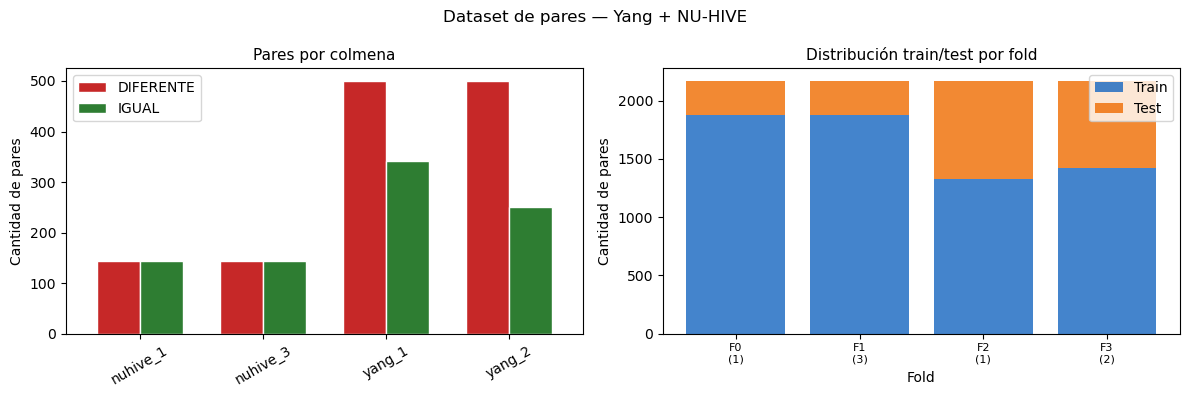

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ── Gráfico 1: pares por colmena ──
conteo = df_pares.groupby(['colmena_origen', 'etiqueta']).size().unstack(fill_value=0)
conteo.columns = ['DIFERENTE', 'IGUAL']
conteo[['DIFERENTE', 'IGUAL']].plot(
    kind='bar', ax=axes[0],
    color=['#C62828', '#2E7D32'],
    edgecolor='white', width=0.7
)
axes[0].set_title('Pares por colmena', fontsize=11)
axes[0].set_xlabel('')
axes[0].set_ylabel('Cantidad de pares')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()

# ── Gráfico 2: tamaño de train/test por fold ──
x = range(n_folds)
axes[1].bar(x, df_resumen_folds['n_train'], label='Train', color='#1565C0', alpha=0.8)
axes[1].bar(x, df_resumen_folds['n_test'],  label='Test',  color='#EF6C00', alpha=0.8,
            bottom=df_resumen_folds['n_train'])
axes[1].set_title('Distribución train/test por fold', fontsize=11)
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('Cantidad de pares')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(
    [f"F{k}\n({row['colmena_test'].split('_')[-1]})" 
     for k, row in df_resumen_folds.iterrows()],
    fontsize=8
)
axes[1].legend()

plt.suptitle('Dataset de pares — Yang + NU-HIVE', fontsize=12)
plt.tight_layout()
plt.show()

---
## 8. Guardar dataset completo de pares

In [10]:
df_pares.to_csv(RUTA_PARES, index=False)

print(f"Dataset de pares guardado en: {RUTA_PARES}")
print(f"Folds guardados en:           {RUTA_FOLDS}/")
print()
print("=" * 55)
print("RESUMEN FINAL — DATASET DE PARES (OE2B-03)")
print("=" * 55)
print(f"  Total pares:          {len(df_pares):,}")
print(f"  DIFERENTE (etiq=0):   {(df_pares['etiqueta']==0).sum():,}")
print(f"  IGUAL     (etiq=1):   {(df_pares['etiqueta']==1).sum():,}")
print(f"  Colmenas:             {df_pares['colmena_origen'].nunique()}")
print(f"  Folds k-hive:         {n_folds}")
print()
print("─── Reglas verificadas ───")
print("  R1 (mismo origen):         ver sección 5")
print("  R2 (sin leakage):          ver sección 6 (leakage=0 en todos los folds)")
print("  R3 (balance 50/50):        ver sección 5")
print("  R4 (DIFERENTE → trans.):   ver sección 5")
print("  R5 (IGUAL → estable):      ver sección 5")
print()
print("─── Próximo paso ───")
print("  OE2B-04: Extracción de features (Mel, MFCC, FFT, CQT)")

Dataset de pares guardado en: ../data/processed/pares/pares_completo.csv
Folds guardados en:           ../data/processed/pares/folds/

RESUMEN FINAL — DATASET DE PARES (OE2B-03)
  Total pares:          2,168
  DIFERENTE (etiq=0):   1,288
  IGUAL     (etiq=1):   880
  Colmenas:             4
  Folds k-hive:         4

─── Reglas verificadas ───
  R1 (mismo origen):         ver sección 5
  R2 (sin leakage):          ver sección 6 (leakage=0 en todos los folds)
  R3 (balance 50/50):        ver sección 5
  R4 (DIFERENTE → trans.):   ver sección 5
  R5 (IGUAL → estable):      ver sección 5

─── Próximo paso ───
  OE2B-04: Extracción de features (Mel, MFCC, FFT, CQT)
